### Encoded MI estimation with Normalization Flow

In [1]:
import torch
from torchvision import datasets, transforms
from models.nn import *
import matplotlib.pyplot as plt
from models.utils import *
from models.maf import *

In [2]:
loss_fn = 'DV_loss' # NWJ_loss ; DV_loss ; NCE_loss; PCM_loss
miest_type = 'all' # 'l1'
img_size = 28
reg = True
refbatch = True

In [ ]:
# load the data
transform = transforms.Compose([
    transforms.Resize(img_size),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# load mnist
train_dataset = datasets.MNIST('../data/', train=True, download=True, transform=transform)

In [4]:
test_labels = 10

In [5]:
grouped_data = {label: [] for label in range(10)}
train_loaders = []

# group the data
for data in train_dataset:
    label = data[1]
    grouped_data[label].append(data)

class_batch_size = 100
for c in range(test_labels):
    train_loaders.append(torch.utils.data.DataLoader(grouped_data[c], batch_size=class_batch_size, shuffle=True))

# construct the train dataset: X, Y are i.i.d. samples from the same class
X = []
Y = []
for c in range(test_labels):
    # for _ in range(10):
    data1, _ = next(iter(train_loaders[c]))
    data2, _ = next(iter(train_loaders[c]))
    X.append(data1)
    Y.append(data2)

X = torch.cat(X)
Y = torch.cat(Y)
XY = torch.cat((X, Y), dim=1)

In [6]:
X.shape, Y.shape

(torch.Size([1000, 1, 28, 28]), torch.Size([1000, 1, 28, 28]))

In [12]:
# move to GPU
net = DNN_Net(input_size=784*2)
optimizer = torch.optim.Adam(net.parameters(), lr=0.0002, betas=(0.5, 0.999))

In [8]:
def get_model(config):
    # TODO: do something about these args
    if config.model.name == 'maf':
        model = MAF(config.model.n_blocks, config.model.input_size, config.model.hidden_size, config.model.n_hidden, None, config.model.activation_fn, config.model.input_order, batch_norm=not config.model.no_batch_norm)
    else:
        raise ValueError('Unrecognized model.')
    return model

In [9]:
import argparse
def dict2namespace(config):
    namespace = argparse.Namespace()
    if isinstance(config, list):
        # from creating config files
        for i in range(len(config)):
            for key, value in config[i].items():
                if isinstance(value, dict):
                    new_value = dict2namespace(value)
                else:
                    new_value = value
                setattr(namespace, key, new_value)
    else:
        # vanilla training
        for key, value in config.items():
            if isinstance(value, dict):
                new_value = dict2namespace(value)
            else:
                new_value = value
            setattr(namespace, key, new_value)
    return namespace

import yaml
import os
with open('./configs/perc0.1.yaml', 'r') as f:
    config = yaml.safe_load(f)
config = dict2namespace(config)
nf_model = get_model(config)

# load the model
pretrained_net_dict = torch.load('./checkpoints/nf_pt/model_state.pt')
new_state_dict = {}
for k, v in pretrained_net_dict.items():
    name = k[7:] # remove `module.`
    new_state_dict[name] = v
# load params
nf_model.load_state_dict(new_state_dict)

<All keys matched successfully>

In [13]:
if torch.cuda.is_available():
    X = X.cuda()
    Y = Y.cuda()
    XY = XY.cuda()
    net.cuda()
    nf_model.cuda()

In [14]:
nf_model(X.reshape(X.shape[0], -1))[0].shape

torch.Size([1000, 784])

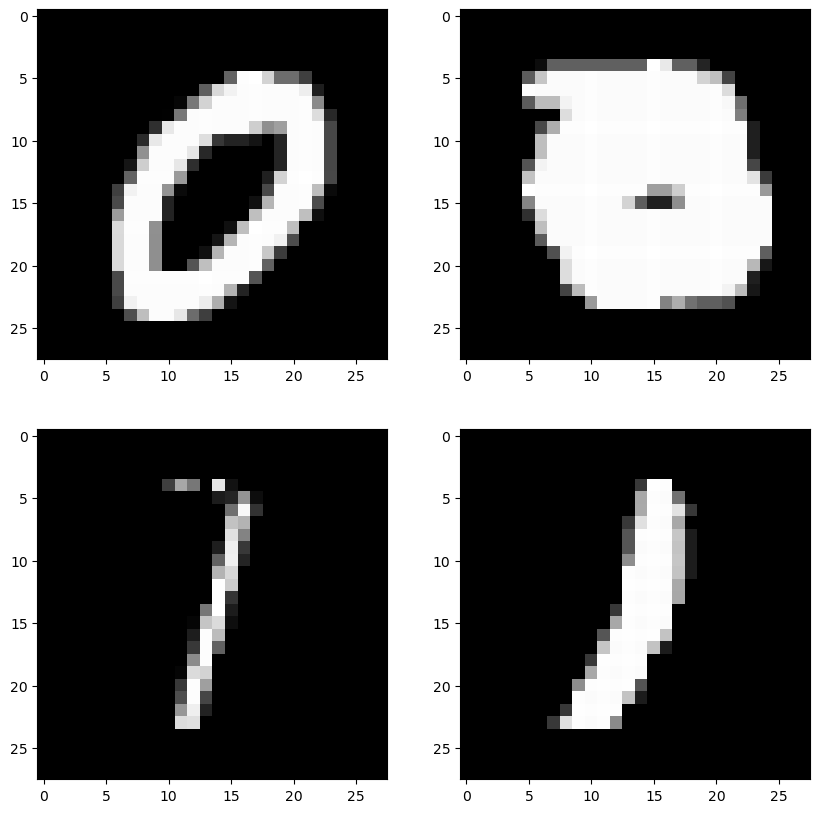

In [15]:
# plot the mnist data X, Y
plt.figure(figsize=(10, 10))
plt.subplot(2, 2, 1)
plt.imshow(X[0][0].cpu().detach().numpy(), cmap='gray')
plt.subplot(2, 2, 2)
plt.imshow(Y[0][0].cpu().detach().numpy(), cmap='gray')
plt.subplot(2, 2, 3)
plt.imshow(X[100][0].cpu().detach().numpy(), cmap='gray')
plt.subplot(2, 2, 4)
plt.imshow(Y[100][0].cpu().detach().numpy(), cmap='gray')
plt.show()


In [ ]:
def code(encoder, data):
    """Obtain the codes from the pixel data.count

    Args:
        - encoder: the encoder of InfoGAN model Q(c|X)
        - data: pixel data

    Return:
        The codes/representation of data.
    """
    _, label, latent_code = encoder(data)
    dis_code = torch.argmax(label, dim=1)
    code_ = torch.cat((latent_code, dis_code.unsqueeze(1).float()), dim=1)
    return code_

def DV_loss(D, x, y, y_ref=None, reg=False, alpha=1.0):
    '''
    D: discriminator
    x: data x
    y: data y
    '''
    # reshuffle y and concatenate with x
    joint_xy = torch.cat((x, y), dim=1)

    if y_ref is None:
        marginal_xy = torch.cat((x, y[torch.randperm(x.size()[0])]), dim=1)
    else:
        marginal_xy = torch.cat((x, y_ref), dim=1)

    # joint_xy = x + y
    # marginal_xy = x + y[torch.randperm(x.size()[0])]
    if reg:
        return -D(joint_xy.view(joint_xy.size(0), -1)).mean() + torch.logsumexp(D(marginal_xy.view(marginal_xy.size(0), -1)), dim=0).mean() - np.log(marginal_xy.shape[0]) + alpha*(torch.logsumexp(D(marginal_xy.view(marginal_xy.size(0), -1)), dim=0).mean() - np.log(marginal_xy.shape[0]))**2
    else:
        return - D(joint_xy.view(joint_xy.size(0), -1)).mean() + torch.logsumexp(D(marginal_xy.view(marginal_xy.size(0), -1)), dim=0).mean() - np.log(marginal_xy.shape[0])

In [19]:
max_iter = 40000
batch_size = 20
ref_batch_size = batch_size
mi_list = []
with torch.no_grad():
    code_X = nf_model(X.reshape(X.shape[0], -1))[0]
    code_Y = nf_model(Y.reshape(Y.shape[0], -1))[0]
# dis_mi = mutual_information(dis_codeX.cpu(), dis_codeY.cpu())

for i in range(max_iter):
    # draw mini-batch data
    idx = resample(X, batch_size, return_idx=True)

    # train
    optimizer.zero_grad()

    # dis_mi = mutual_information(dis_codex.cpu(), dis_codey.cpu())
    if refbatch:
        idx_ref = resample(Y, ref_batch_size, return_idx=True)
        batch_codex = code_X[idx]
        batch_codey = code_Y[idx]
        refbatch_codey = code_Y[idx_ref]
        loss = eval(loss_fn)(net, batch_codex, batch_codey, refbatch_codey, reg=reg)
    else:
        loss = eval(loss_fn)(net, batch_codex, batch_codey, reg=reg)
    loss.backward()

    # torch.nn.utils.clip_grad_norm_(net.parameters(), 0.02)
    optimizer.step()
    with torch.no_grad():
        if miest_type == 'all':
            mi_list.append(-eval(loss_fn)(net, code_X, code_Y).item())
        elif miest_type == 'l1':
            mi_list.append(mi_estimate(net, torch.cat((code_X, code_Y), dim=1)).item())
    if i % 200 == 0:
        print('iter: {}, mi estimation: {}'.format(i, mi_list[-1]))

iter: 0, mi estimation: 9.918212890625e-05
iter: 200, mi estimation: 0.2595090866088867
iter: 400, mi estimation: 0.4533352851867676
iter: 600, mi estimation: 0.7640290260314941
iter: 800, mi estimation: 0.7079629898071289
iter: 1000, mi estimation: 0.8949451446533203
iter: 1200, mi estimation: 0.991368293762207
iter: 1400, mi estimation: 1.0906915664672852
iter: 1600, mi estimation: 1.1903128623962402
iter: 1800, mi estimation: 1.322187900543213
iter: 2000, mi estimation: 1.435258388519287
iter: 2200, mi estimation: 1.3926310539245605
iter: 2400, mi estimation: 1.3481221199035645
iter: 2600, mi estimation: 1.5137004852294922
iter: 2800, mi estimation: 1.537074089050293
iter: 3000, mi estimation: 1.443127155303955
iter: 3200, mi estimation: 1.5770373344421387
iter: 3400, mi estimation: 1.829317569732666
iter: 3600, mi estimation: 1.559983253479004
iter: 3800, mi estimation: 1.8853774070739746
iter: 4000, mi estimation: 2.000760555267334
iter: 4200, mi estimation: 1.9321560859680176
ite

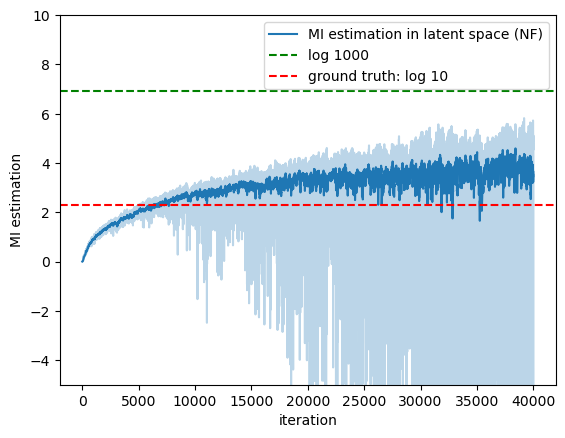

The figure is saved at ./figs/NF_miall_label10bs20regTruerefTrue.png


In [23]:
import pandas as pd
import math

EMA_SPAN = 50
p1 = plt.plot(mi_list, alpha=0.3)[0]
mis_smooth = pd.Series(mi_list).ewm(span=EMA_SPAN).mean()
plt.plot(mis_smooth, c=p1.get_color(), label='MI estimation in latent space (NF)')
plt.axhline(math.log(XY.shape[0]), c='g', ls='--', label=f'log {XY.shape[0]}')
# plt.axhline(math.log(batch_size), ls='--', label=f'log {batch_size}')
# plt.ylim(0, 2*math.log(batch_size))
plt.axhline(math.log(test_labels), c='r', ls='--', label=f'ground truth: log {test_labels}')
plt.ylim(-5, 10)
plt.xlabel('iteration')
plt.ylabel('MI estimation')
plt.legend()
# plt.title(f'labels:{test_labels} {loss_fn}')
# plt.legend(['raw', 'MI EMA', ])
plt.savefig(f'./figs/NF_mi{miest_type}_label{test_labels}bs{batch_size}reg{reg}ref{refbatch}.pdf')
plt.show()
print(f'The figure is saved at ./figs/NF_mi{miest_type}_label{test_labels}bs{batch_size}reg{reg}ref{refbatch}.png')

In [12]:
chkpt_name = './checkpoints/latent_DV.pt'
overwrite = True  # set to True to overwrite previously stored results
if overwrite or not os.path.exists(chkpt_name):
    torch.save({
        'mi_list': mi_list,
        'net_state_list': net.state_dict(),
        'optimizer_state_list': optimizer.state_dict(),
    }, chkpt_name)
    print('Current results saved.')

Current results saved.
